<a href="https://colab.research.google.com/github/Sayak-coder/HateSpeech-detection/blob/main/StereoQueerEval_EN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [74]:
!pip install tensorflow

In [75]:
import pandas as pd

In [76]:
df = pd.read_csv('/content/StereoQueerEval_EN_training.tsv', sep='\t')
df.head()

,StereoQueerEval_id,yt_title,yt_description,yt_comment,stereotype,hate_speech,target
0,training_EN_0001,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes,yes_explicit,individual_l
1,training_EN_0002,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes,yes_implicit,group_t
2,training_EN_0003,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes,yes_implicit,"group_l,g"
3,training_EN_0004,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes,yes_implicit,group_l
4,training_EN_0005,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes,yes_implicit,group_g


In [77]:
df = df.drop(['hate_speech', 'target','StereoQueerEval_id'], axis=1)
df.head()

,yt_title,yt_description,yt_comment,stereotype
0,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...,yes
1,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...,yes
2,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall...",yes
3,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...,yes
4,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him,yes


In [78]:
df.isnull().sum()

,0
yt_title,0
yt_description,0
yt_comment,0
stereotype,0


In [79]:
df.dropna(inplace=True)

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2989 entries, 0 to 2988
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   yt_title        2989 non-null   object
 1   yt_description  2989 non-null   object
 2   yt_comment      2989 non-null   object
 3   stereotype      2989 non-null   object
dtypes: object(4)
memory usage: 93.5+ KB


In [81]:
df.shape

(2989, 4)

In [82]:
import tensorflow as tf
tf.__version__

'2.21.0'

In [83]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dense
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [84]:
X = df.drop('stereotype',axis=1)
y = df['stereotype']

In [85]:
X

,yt_title,yt_description,yt_comment
0,[CHANNEL]: Lesbian denied communion at funeral,[CHANNEL] speaks to Barbara Johnson who says a...,She's living in unrepentant defiance to God's ...
1,GOP Congresswoman uses anti-trans slur in Hous...,Rep. Nancy Mace (R-SC) was challenged by Rep. ...,Rep Mace: Keep on being dedicated to truth and...
2,Kevin Smith defends his gay brother,"Kevin Smith supports gay rights, and defends h...","We all need Jesus, He said no homosexual shall..."
3,Judge removes child from gay foster parents,A Utah judge removed a foster child from a les...,So can two black men adopt a little white girl...
4,Chechen leader Ramzan Kadyrov questioned on 'g...,Chechnya's leader Ramzan Kadyrov is questioned...,Of course west and US will hate him
...,...,...,...
2984,Lesbian magazine Curve 'saved people from lone...,A new documentary called Ahead of the Curve ch...,Somewhere in germany Kolon some guy has taken ...
2985,TURKEY: RIOT POLICE BREAK UP GAY PRIDE PARADE,"To License This Clip, Click Here: [URL]",Respect from Uzbekistan
2986,Argentina’s transgender soccer star,"Meet Mara Gomez, Argentina’s first transgender...",Yeah.. super fair to all those REAL women.
2987,Model comes out as intersex,Model Hanne Gaby Odiele has revealed that she ...,Good for her. Everyone has the right to be wan...


In [86]:
y

,stereotype
0,yes
1,yes
2,yes
3,yes
4,yes
...,...
2984,no
2985,no
2986,yes
2987,no


In [87]:
import nltk
import re
from nltk.corpus import stopwords

In [88]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [89]:
len(X)

2989

#different corpus for different column

In [90]:
from nltk.stem.porter import PorterStemmer

stemmer = PorterStemmer()
corpus_title = []
corpus_description = []
corpus_comment = []

# Process yt_title
for text in X['yt_title']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_title.append(review)

# Process yt_description
for text in X['yt_description']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_description.append(review)

# Process yt_comment
for text in X['yt_comment']:
    review = re.sub('[^a-zA-Z]', ' ', str(text))
    review = review.lower().split()
    review = [stemmer.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus_comment.append(review)

In [91]:
voc_size = 5000

In [92]:
one_hot_rep_comment=[one_hot(word,voc_size)for word in corpus_comment]
one_hot_rep_description=[one_hot(word,voc_size)for word in corpus_description]
one_hot_rep_title=[one_hot(word,voc_size)for word in corpus_title]

In [93]:
print(corpus_comment[1])
print(one_hot_rep_comment[1])

rep mace keep dedic truth polit correct propaganda thank leadership
[1120, 137, 4034, 808, 1687, 3599, 453, 4765, 4288, 1482]


In [94]:
max_length=30
embedded_doc_comment=pad_sequences(one_hot_rep_comment,padding='post',maxlen=max_length)
embedded_doc_description=pad_sequences(one_hot_rep_description,padding='post',maxlen=max_length)
embedded_doc_title=pad_sequences(one_hot_rep_title,padding='post',maxlen=max_length)

In [95]:
print(embedded_doc_title)
print(embedded_doc_description)
print(embedded_doc_comment)

[[ 590 1557 4601 ...    0    0    0]
 [4050   86 2719 ...    0    0    0]
 [1600 1773 1243 ...    0    0    0]
 ...
 [4412 2143 1094 ...    0    0    0]
 [ 155 2073  962 ...    0    0    0]
 [1401 4189 2402 ...    0    0    0]]
[[ 590  548 3309 ...    0    0    0]
 [3973 2890 2719 ... 4066  590 4109]
 [1600 1773 1268 ...    0    0    0]
 ...
 [ 590 1354 3333 ...  590  896  943]
 [ 155 3941 2536 ...    0    0    0]
 [ 139 3525 1401 ...    0    0    0]]
[[1826 2138 1862 ...    0    0    0]
 [1120  137 4034 ...    0    0    0]
 [4288 3907 3232 ...    0    0    0]
 ...
 [2407 2299 2822 ...    0    0    0]
 [4775 3765 3190 ...    0    0    0]
 [4664  750  521 ...    0    0    0]]


In [96]:
embedding_vector_features=40
model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(LSTM(150))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [97]:
embeded_doc = pd.DataFrame({
    'yt_title': list(embedded_doc_title),
    'yt_description': list(embedded_doc_description),
    'yt_comment': list(embedded_doc_comment)
})
display(embeded_doc.head())

,yt_title,yt_description,yt_comment
0,"[590, 1557, 4601, 3496, 3215, 0, 0, 0, 0, 0, 0...","[590, 548, 3309, 4614, 2070, 1735, 4601, 3496,...","[1826, 2138, 1862, 3958, 1349, 4385, 0, 0, 0, ..."
1,"[4050, 86, 2719, 1508, 2474, 2510, 3249, 4811,...","[3973, 2890, 2719, 1508, 2143, 2510, 693, 2967...","[1120, 137, 4034, 808, 1687, 3599, 453, 4765, ..."
2,"[1600, 1773, 1243, 1692, 3572, 0, 0, 0, 0, 0, ...","[1600, 1773, 1268, 1692, 3190, 1243, 3572, 213...","[4288, 3907, 3232, 4595, 2294, 3540, 2790, 395..."
3,"[1879, 1971, 4560, 1692, 1191, 1836, 0, 0, 0, ...","[620, 1879, 1971, 1191, 4560, 1557, 3726, 2070...","[2906, 224, 933, 2137, 800, 330, 1352, 3631, 4..."
4,"[972, 3421, 2707, 2442, 4031, 1692, 1936, 590,...","[3190, 1226, 3092, 3190, 2877, 1577, 4694, 244...","[1703, 3363, 1375, 506, 0, 0, 0, 0, 0, 0, 0, 0..."


In [98]:
y = y.map({'no': 0, 'yes': 1})

In [99]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(embeded_doc,y,test_size=0.2,random_state=45)

In [100]:
X_train.shape,X_test.shape

((2391, 3), (598, 3))

In [101]:
import numpy as np

X_train = np.hstack([
    np.stack(X_train['yt_title'].values),
    np.stack(X_train['yt_description'].values),
    np.stack(X_train['yt_comment'].values)
])

X_test = np.hstack([
    np.stack(X_test['yt_title'].values),
    np.stack(X_test['yt_description'].values),
    np.stack(X_test['yt_comment'].values)
])

In [102]:
epochs=20
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=epochs,batch_size=64)

Epoch 1/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 20s 452ms/step - accuracy: 0.5742 - loss: 0.6812 - val_accuracy: 0.5686 - val_loss: 0.6781
Epoch 2/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 11s 195ms/step - accuracy: 0.6043 - loss: 0.6716 - val_accuracy: 0.6104 - val_loss: 0.6694
Epoch 3/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 209ms/step - accuracy: 0.6855 - loss: 0.6063 - val_accuracy: 0.6087 - val_loss: 0.6586
Epoch 4/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.7520 - loss: 0.5336 - val_accuracy: 0.6672 - val_loss: 0.6401
Epoch 5/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 207ms/step - accuracy: 0.8038 - loss: 0.4389 - val_accuracy: 0.6839 - val_loss: 0.6284
Epoch 6/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 165ms/step - accuracy: 0.8578 - loss: 0.3569 - val_accuracy: 0.6873 - val_loss: 0.6790
Epoch 7/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 208ms/step - accuracy: 0.8846 - loss: 0.3025 - val_accuracy: 0.6706 - val_loss: 0.8506
Epoch 8/20
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 185ms/step - accuracy: 0.8900 - loss: 0.2946 - val_accuracy: 

In [103]:
y_pred=model.predict(X_test)

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step


In [104]:
import numpy as np
y_pred=np.where(y_pred>0.5,1,0)

In [105]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_pred,y_test))

0.6488294314381271


In [106]:
from sklearn.metrics import classification_report
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.71      0.67      0.69       345
           1       0.58      0.62      0.60       253

    accuracy                           0.65       598
   macro avg       0.64      0.64      0.64       598
weighted avg       0.65      0.65      0.65       598



#using Dropouts


In [107]:
from tensorflow.keras.layers import Dropout
embedding_vector_features=40
model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(Dropout(0.3))
model.add(LSTM(150))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [108]:
epochs=15
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=epochs,batch_size=64)

Epoch 1/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 219ms/step - accuracy: 0.5529 - loss: 0.6842 - val_accuracy: 0.5753 - val_loss: 0.6841
Epoch 2/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 9s 188ms/step - accuracy: 0.5910 - loss: 0.6769 - val_accuracy: 0.5786 - val_loss: 0.6812
Epoch 3/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 17s 360ms/step - accuracy: 0.6085 - loss: 0.6721 - val_accuracy: 0.5903 - val_loss: 0.6702
Epoch 4/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 15s 212ms/step - accuracy: 0.5859 - loss: 0.7809 - val_accuracy: 0.5686 - val_loss: 0.6896
Epoch 5/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.5500 - loss: 0.6854 - val_accuracy: 0.5485 - val_loss: 0.6855
Epoch 6/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 211ms/step - accuracy: 0.5855 - loss: 0.6809 - val_accuracy: 0.5485 - val_loss: 0.6858
Epoch 7/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step - accuracy: 0.6002 - loss: 0.6679 - val_accuracy: 0.5786 - val_loss: 0.6739
Epoch 8/15
38/38 ━━━━━━━━━━━━━━━━━━━━ 8s 195ms/step - accuracy: 0.6788 - loss: 0.5977 - val_accuracy:

In [109]:
y_pred=model.predict(X_test)

19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 146ms/step


In [111]:
import numpy as np
y_pred=np.where(y_pred>0.5,1,0)

In [112]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_pred,y_test))

0.6672240802675585


In [113]:
from sklearn.metrics import classification_report
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

           0       0.74      0.68      0.71       354
           1       0.58      0.64      0.61       244

    accuracy                           0.67       598
   macro avg       0.66      0.66      0.66       598
weighted avg       0.67      0.67      0.67       598



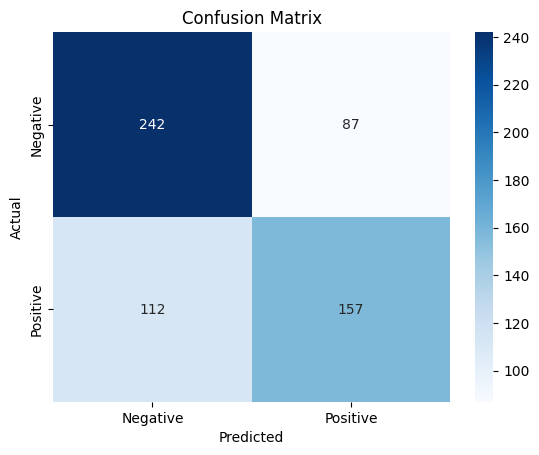

In [115]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()